
# Clase 7: Aprendizaje no supervisado

## Agrupamiento de datos de navegación robótica

### Objetivo

Implementar y analizar los algoritmos K-Means y DBSCAN para identificar patrones de agrupamiento en las lecturas de los 24 sensores del robot SCITOS-G5.

### Dataset

Se utiliza el conjunto de datos Wall-Following Robot Navigation, compuesto por 5456 registros y 24 variables correspondientes a sensores.

### Algoritmos implementados

- **K-Means:** agrupamiento por proximidad a centroides.
- **DBSCAN:** agrupamiento basado en densidad y detección de ruido.

Los algoritmos utilizan las características de los sensores sin emplear las etiquetas originales de navegación durante el entrenamiento.


In [3]:

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.decomposition import PCA

# Rutas del proyecto
BASE_DIR = Path.cwd().resolve().parent

DATA_PATH = BASE_DIR / "data" / "raw" / "sensor_readings_24.data"
MODELS_DIR = BASE_DIR / "models"

# Cargar dataset
columnas = [f"sensor_{i}" for i in range(1, 25)] + ["clase"]

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=columnas
)

X = df.drop(columns=["clase"])

# Cargar modelos y escalador
scaler = joblib.load(MODELS_DIR / "unsupervised_scaler.pkl")
kmeans = joblib.load(MODELS_DIR / "kmeans.pkl")
dbscan = joblib.load(MODELS_DIR / "dbscan.pkl")

# Preparar datos
X_scaled = scaler.transform(X)

# Obtener etiquetas
etiquetas_kmeans = kmeans.predict(X_scaled)
etiquetas_dbscan = dbscan.labels_

print("Dataset cargado correctamente.")
print("Registros:", X_scaled.shape[0])
print("Sensores:", X_scaled.shape[1])
print("Clústeres K-Means:", len(set(etiquetas_kmeans)))
print("Clústeres DBSCAN:", len(set(etiquetas_dbscan) - {-1}))


Dataset cargado correctamente.
Registros: 5456
Sensores: 24
Clústeres K-Means: 4
Clústeres DBSCAN: 32


PCA aplicado correctamente.
Dimensiones originales: (5456, 24)
Dimensiones reducidas: (5456, 2)
Varianza explicada por PCA: 47.43 %


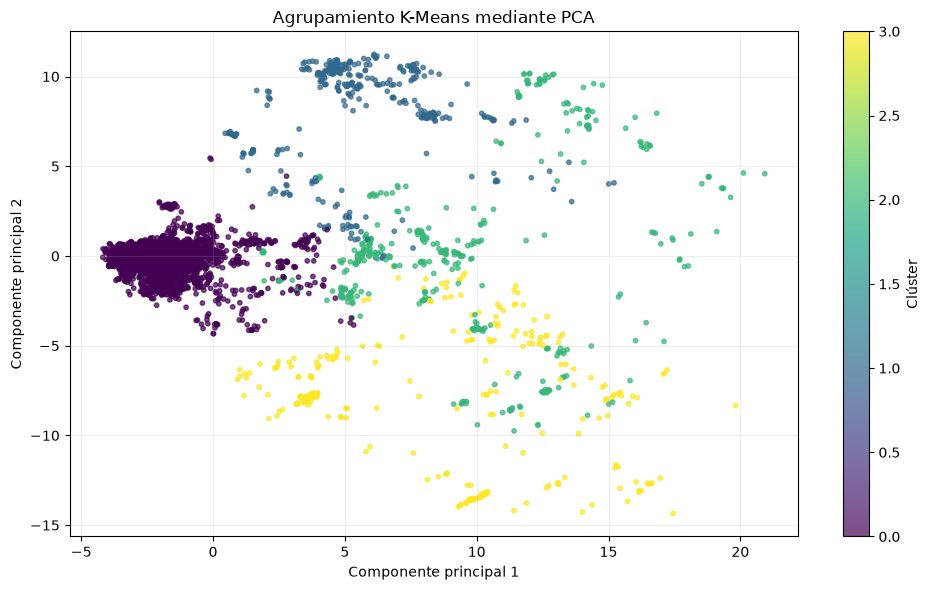

In [4]:

# Reducir las 24 variables a 2 componentes principales
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA aplicado correctamente.")
print("Dimensiones originales:", X_scaled.shape)
print("Dimensiones reducidas:", X_pca.shape)

print(
    "Varianza explicada por PCA:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

# Visualizar K-Means
plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=etiquetas_kmeans,
    cmap="viridis",
    s=10,
    alpha=0.7
)

plt.title("Agrupamiento K-Means mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.colorbar(label="Clúster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


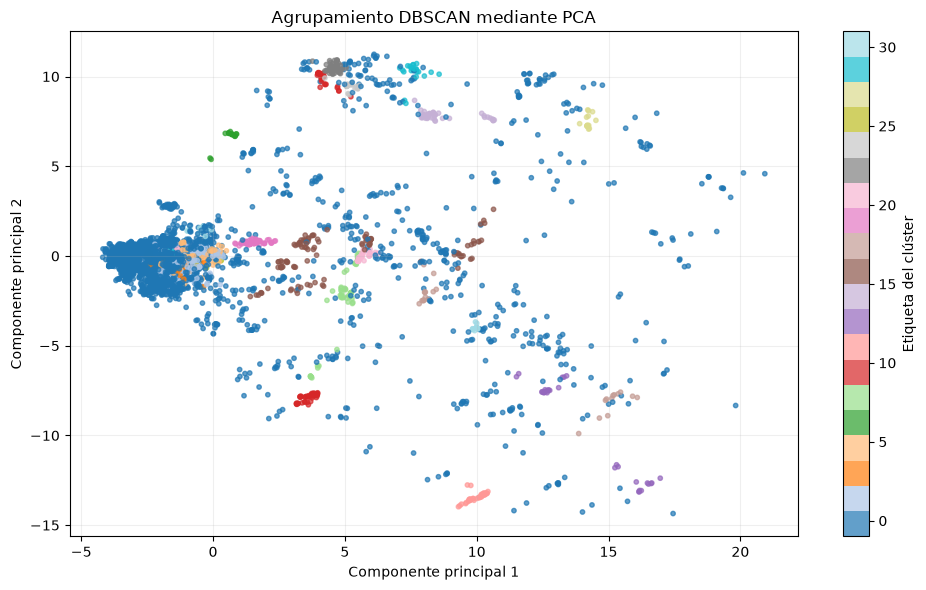

Clústeres DBSCAN: 32
Registros considerados ruido: 849


In [5]:

# Visualizar los agrupamientos de DBSCAN
plt.figure(figsize=(10, 6))

grafica = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=etiquetas_dbscan,
    cmap="tab20",
    s=10,
    alpha=0.7
)

plt.title("Agrupamiento DBSCAN mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

plt.colorbar(grafica, label="Etiqueta del clúster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Clústeres DBSCAN:", len(set(etiquetas_dbscan) - {-1}))
print("Registros considerados ruido:", np.sum(etiquetas_dbscan == -1))


## Análisis y conclusión de la Clase 7

En esta práctica se implementaron dos algoritmos de aprendizaje no supervisado, K-Means y DBSCAN, utilizando el conjunto de datos Wall-Following Robot Navigation, compuesto por 5456 registros y 24 variables correspondientes a sensores robóticos.

**K-Means** identificó cuatro clústeres y obtuvo un Silhouette Score de 0.4743, lo que sugiere una separación moderada entre los grupos encontrados.

**DBSCAN**, utilizando los parámetros `eps=3.0` y `min_samples=10`, identificó 32 clústeres y clasificó 849 registros como ruido, equivalentes aproximadamente al 15.56 % del conjunto de datos. Su Silhouette Score estimado fue de 0.1834, calculado sobre una muestra de los registros agrupados.

Mediante PCA se redujeron las 24 variables a dos componentes principales para visualizar los agrupamientos. Las gráficas permitieron observar una estructura más compacta en una parte de los datos agrupados por K-Means, mientras que DBSCAN identificó múltiples agrupaciones pequeñas y registros considerados ruido.

Los resultados sugieren que K-Means presenta una estructura de agrupamiento más favorable según la métrica obtenida. Sin embargo, las puntuaciones Silhouette no son directamente equivalentes debido a las diferencias en los registros utilizados para su cálculo.

**En conclusión**, ambos algoritmos permitieron identificar patrones sin utilizar las etiquetas originales de navegación. K-Means presentó resultados prometedores para segmentar las lecturas de los sensores, mientras que DBSCAN permitió explorar agrupaciones basadas en densidad y detectar posibles valores atípicos. Como trabajo futuro, se recomienda optimizar los parámetros y aplicar evaluaciones comparables para determinar la configuración más adecuada.

### Conclusiones de la Clase 7

Se implementaron los algoritmos de aprendizaje no supervisado K-Means y DBSCAN para analizar las lecturas de 24 sensores de un robot móvil, utilizando un conjunto de datos de 5456 registros.

Mediante el método del codo se analizaron valores de `k` entre 2 y 10, seleccionando `k=4` como una alternativa razonable para el entrenamiento de K-Means. Este algoritmo obtuvo un Silhouette Score de 0.4709, evidenciando una separación moderada de los agrupamientos.

Por su parte, DBSCAN identificó 32 clústeres y clasificó 849 registros como ruido, con un Silhouette Score de 0.1834 calculado sobre los registros no considerados ruido.

Los resultados sugieren que K-Means genera agrupamientos mejor definidos bajo los parámetros utilizados. DBSCAN, en cambio, permite identificar observaciones que no pertenecen a regiones suficientemente densas. Ambos algoritmos ofrecen perspectivas diferentes sobre la estructura de los datos.

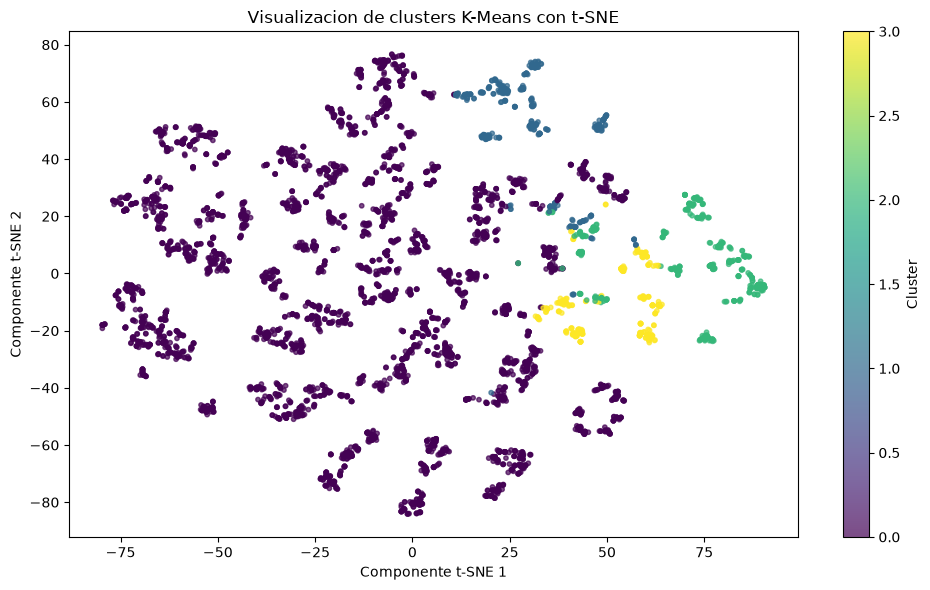

In [6]:

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

# Reducir los datos a dos dimensiones con t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

# Obtener los grupos de K-Means
etiquetas_kmeans = kmeans.predict(X_scaled)

# Visualizar los grupos
plt.figure(figsize=(10, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=etiquetas_kmeans,
    cmap="viridis",
    s=10,
    alpha=0.7
)

plt.title("Visualizacion de clusters K-Means con t-SNE")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()


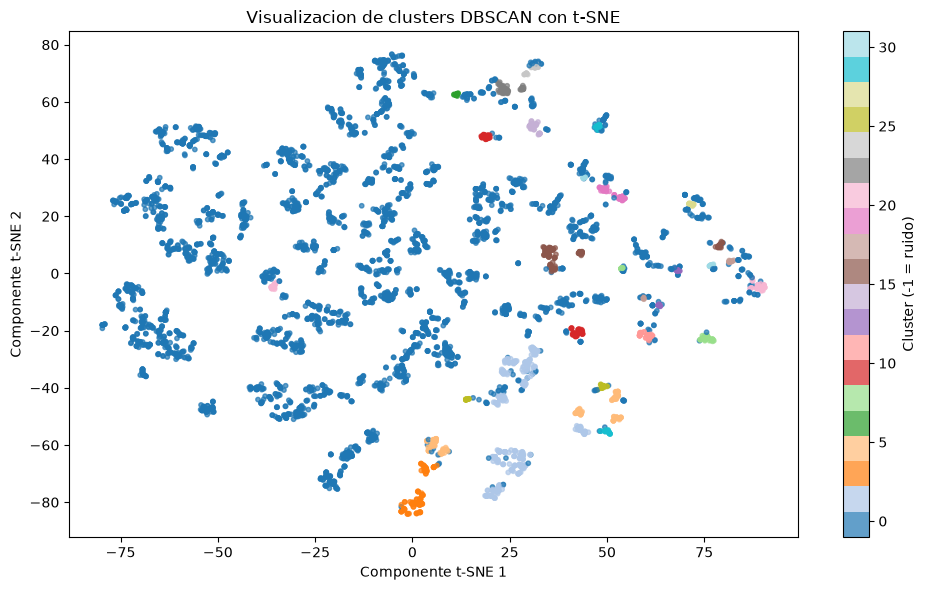

In [7]:

# Visualizacion de DBSCAN mediante t-SNE

# Obtener las etiquetas generadas por DBSCAN
# DBSCAN no tiene predict(), por eso usamos labels_
etiquetas_dbscan = dbscan.labels_

plt.figure(figsize=(10, 6))

grafica = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=etiquetas_dbscan,
    cmap="tab20",
    s=10,
    alpha=0.7
)

plt.title("Visualizacion de clusters DBSCAN con t-SNE")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")

plt.colorbar(grafica, label="Cluster (-1 = ruido)")
plt.tight_layout()
plt.show()


In [8]:

import time
import json
import numpy as np
from pathlib import Path

# Carpeta para guardar los resultados
OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Usar una observacion como entrada
muestra = X_scaled[0:1]

# Realizar 100 predicciones con K-Means
tiempos = []

# Calentamiento del modelo
for _ in range(5):
    kmeans.predict(muestra)

for _ in range(100):
    inicio = time.perf_counter()
    kmeans.predict(muestra)
    fin = time.perf_counter()

    tiempos.append((fin - inicio) * 1000)

# Calcular estadisticas
resultados_latencia = {
    "modelo": "K-Means",
    "numero_predicciones": 100,
    "unidad": "milisegundos",
    "latencia_promedio_ms": float(np.mean(tiempos)),
    "latencia_minima_ms": float(np.min(tiempos)),
    "latencia_maxima_ms": float(np.max(tiempos))
}

# Guardar resultados en JSON
ruta_json = OUTPUT_DIR / "benchmark_latency.json"

with open(ruta_json, "w", encoding="utf-8") as archivo:
    json.dump(
        resultados_latencia,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("========== BENCHMARK DE LATENCIA ==========")
print("Modelo:", resultados_latencia["modelo"])
print("Predicciones:", resultados_latencia["numero_predicciones"])
print(
    "Latencia promedio:",
    round(resultados_latencia["latencia_promedio_ms"], 4),
    "ms"
)
print(
    "Latencia minima:",
    round(resultados_latencia["latencia_minima_ms"], 4),
    "ms"
)
print(
    "Latencia maxima:",
    round(resultados_latencia["latencia_maxima_ms"], 4),
    "ms"
)

print("\nArchivo guardado en:", ruta_json)


========== BENCHMARK DE LATENCIA ==========
Modelo: K-Means
Predicciones: 100
Latencia promedio: 0.4685 ms
Latencia minima: 0.2157 ms
Latencia maxima: 1.5485 ms

Archivo guardado en: ..\data\processed\benchmark_latency.json


### Conclusiones de la Clase 8

En esta práctica se analizaron los resultados de los algoritmos K-Means y DBSCAN utilizando técnicas de reducción de dimensionalidad PCA y t-SNE para representar gráficamente los agrupamientos de las lecturas de 24 sensores de un robot móvil.

K-Means permitió identificar cuatro clústeres y obtuvo un Silhouette Score de 0.4709. Por su parte, DBSCAN identificó 32 clústeres y 849 registros considerados ruido, con un Silhouette Score de 0.1834.

Las visualizaciones PCA y t-SNE facilitaron la exploración de la distribución de los datos y las diferencias entre los agrupamientos generados por ambos algoritmos. Estas representaciones permiten analizar visualmente la estructura de los clústeres, aunque no constituyen por sí solas una medida definitiva de su calidad.

Finalmente, se realizó un benchmark de latencia mediante 100 predicciones individuales de K-Means. Los resultados se almacenaron en el archivo `benchmark_latency.json`, permitiendo evaluar el tiempo de inferencia del modelo en el entorno de ejecución utilizado.